# Proyecto RaSa
## Entregable 1 · Perfilamiento de datos

**Objetivo:** explorar e interpretar F1–F4 de `RaSaTransaccional`, con PySpark y consultas.

En este primer entregable el alcance comprende estructura, volumen, granularidad, cardinalidades, cobertura temporal, distribuciones, estadísticos, nulos y duplicados exploratorios.

In [82]:
# Dependencias para instalar en el entorno de ejecución colab
%pip -q install "pyspark[connect]~=4.0.0" pandas matplotlib

In [ ]:
# Credenciales personales
HOST = '157.253.236.120'
PORT = 8080
DATABASE = 'RaSaTransaccional'
USER = '' # ejemplo: 'DB_202615_....'
PASSWORD = ''

In [84]:
# Librerias para conectar el spark con MySQL
import urllib.request
from pathlib import Path
import pandas as pd
from functools import reduce
from IPython.display import display, Markdown
from pyspark.sql import SparkSession, functions as F, types as T

# Conector MySQL
jar = Path('/content/mysql-connector-j-8.4.0.jar')
if not jar.exists():
    urllib.request.urlretrieve(
        'https://repo.maven.apache.org/maven2/com/mysql/mysql-connector-j/8.4.0/mysql-connector-j-8.4.0.jar', str(jar))
# Creacion app Spark
spark = (SparkSession.builder.appName('Proyecto RaSa')
         .config('spark.jars', str(jar)).getOrCreate())
# Configuracion Spark
spark.conf.set('spark.sql.session.timeZone', 'UTC')

# Conexion MySQL desde Spark
URL = f'jdbc:mysql://{HOST}:{PORT}/{DATABASE}?useSSL=false&allowPublicKeyRetrieval=true&serverTimezone=UTC&connectTimeout=20000&socketTimeout=300000'
PROPS = {'user': USER, 'password': PASSWORD, 'driver': 'com.mysql.cj.jdbc.Driver',
         'sessionVariables': 'transaction_read_only=ON'}

# Consultas de solo lectura
def lectura(sql):
    return spark.read.jdbc(URL, f'({sql}) AS consulta_rasa', properties=PROPS)

# Funciones de apoyo
def qi(nombre):
    return '`' + nombre.replace('`', '``') + '`'

def col(nombre):
    return F.col(qi(nombre))

def comentario(texto):
    display(Markdown(texto))

def tabla(df, limite=30):
    display(df.limit(limite).toPandas())

# Verificacion de conexion
tabla(lectura('SELECT DATABASE() AS base_actual, @@session.transaction_read_only AS solo_lectura'))


,base_actual,solo_lectura
0,RaSaTransaccional,1


## 1.1 Inventario tablas a revosar y significado de una fila

Se inspeccionan las cuatro fuentes del enunciado y sus metadatos. Se consultan los comentarios de columnas disponibles en MySQL por si existe explicación adicional de los datos. Adicionalmente se revisan relaciones entre tablas.

* De a cuerdo al enunciado del caso RaSa se estima que:

| Fuente | Tabla | Significado provisional de una fila | Relevancia |
|---|---|---|---|
| F1 | FuenteAreasDeServicio_Copia_E | Registro de un área de servicio y sus atributos geográficos, grupo o vigencia si existen | Cobertura y concentración de planes |
| F2 | FuenteTiposBeneficio_Copia_E | Registro de un tipo de beneficio, condiciones y vigencia si existe | Comparación y evolución de beneficios |
| F3 | FuentePlanesBeneficio_Copia_E | Registro de un beneficio ofrecido por un plan, con condiciones y vigencia si existen; no equivale necesariamente a un plan único | Costos y oferta de planes |
| F4 | FuenteCondicionesDePago_Copia_E | Registro del catálogo de condiciones de pago según el tipo y código disponibles | Interpretación de copago y coseguro |


In [85]:
# Fuentes del proyecto
FUENTES = {
    'F1': 'FuenteAreasDeServicio_Copia_E',
    'F2': 'FuenteTiposBeneficio_Copia_E',
    'F3': 'FuentePlanesBeneficio_Copia_E',
    'F4': 'FuenteCondicionesDePago_Copia_E',
}
lista = ','.join("'" + t + "'" for t in FUENTES.values())
# Consulta de metadatos
metadatos = lectura(f"""SELECT TABLE_NAME, ORDINAL_POSITION, COLUMN_NAME, COLUMN_TYPE,
    IS_NULLABLE, COLUMN_KEY, COLUMN_COMMENT FROM information_schema.COLUMNS
    WHERE TABLE_SCHEMA = '{DATABASE}' AND TABLE_NAME IN ({lista})""").toPandas()
faltantes = set(FUENTES.values()) - set(metadatos['TABLE_NAME'])
if faltantes:
    raise RuntimeError(f'Tablas no visibles en {DATABASE}: {sorted(faltantes)}. Revisar permisos y nombres.')
# Lectura de fuentes
datos = {f: lectura(f'SELECT * FROM {qi(DATABASE)}.{qi(t)}') for f, t in FUENTES.items()}
# Mostrar estructura
for fuente, nombre in FUENTES.items():
    comentario(f'### {fuente} · {nombre}')
    display(metadatos[metadatos.TABLE_NAME == nombre].sort_values('ORDINAL_POSITION'))


### F1 · FuenteAreasDeServicio_Copia_E

,TABLE_NAME,ORDINAL_POSITION,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE,COLUMN_KEY,COLUMN_COMMENT
5,FuenteAreasDeServicio_Copia_E,1,IdAreaDeServicio_T,int,YES,,
7,FuenteAreasDeServicio_Copia_E,2,NombreAreaDeServicio,text,YES,,
6,FuenteAreasDeServicio_Copia_E,3,IdGeografia_T,int,YES,,
1,FuenteAreasDeServicio_Copia_E,4,Condado,text,YES,,
3,FuenteAreasDeServicio_Copia_E,5,Estado,text,YES,,
8,FuenteAreasDeServicio_Copia_E,6,PoblacionAct,float,YES,,
0,FuenteAreasDeServicio_Copia_E,7,Area,float,YES,,
2,FuenteAreasDeServicio_Copia_E,8,Densidad,float,YES,,
4,FuenteAreasDeServicio_Copia_E,9,Fecha,int,YES,,


### F2 · FuenteTiposBeneficio_Copia_E

,TABLE_NAME,ORDINAL_POSITION,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE,COLUMN_KEY,COLUMN_COMMENT
28,FuenteTiposBeneficio_Copia_E,1,IdTipoBeneficio_T,int,YES,,
29,FuenteTiposBeneficio_Copia_E,2,Nombre,text,YES,,
31,FuenteTiposBeneficio_Copia_E,3,UnidadDelLimite,text,YES,,
23,FuenteTiposBeneficio_Copia_E,4,EsEHB,text,YES,,
24,FuenteTiposBeneficio_Copia_E,5,EstaCubiertaPorSeguro,text,YES,,
30,FuenteTiposBeneficio_Copia_E,6,TieneLimiteCuantitativo,text,YES,,
25,FuenteTiposBeneficio_Copia_E,7,ExcluidoDelDesembolsoMaximoDentroDeLaRed,text,YES,,
26,FuenteTiposBeneficio_Copia_E,8,ExcluidoDelDesembolsoMaximoFueraDeLaRed,text,YES,,
27,FuenteTiposBeneficio_Copia_E,9,Fecha,int,YES,,


### F3 · FuentePlanesBeneficio_Copia_E

,TABLE_NAME,ORDINAL_POSITION,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE,COLUMN_KEY,COLUMN_COMMENT
20,FuentePlanesBeneficio_Copia_E,1,IdTipoBeneficio_T,bigint,YES,,
14,FuentePlanesBeneficio_Copia_E,2,IdAreaDeServicio_T,bigint,YES,,
15,FuentePlanesBeneficio_Copia_E,3,IdCondicionDePagoCopago_T,int,YES,,
16,FuentePlanesBeneficio_Copia_E,4,IdCondicionDePagoCoseguro_T,int,YES,,
17,FuentePlanesBeneficio_Copia_E,5,IdNivelServicio_T,int,YES,,
18,FuentePlanesBeneficio_Copia_E,6,IdPlan_T,text,YES,,
13,FuentePlanesBeneficio_Copia_E,7,Fecha,text,YES,,
19,FuentePlanesBeneficio_Copia_E,8,IdProveedor_T,int,YES,,
21,FuentePlanesBeneficio_Copia_E,9,valorCopago,int,YES,,
22,FuentePlanesBeneficio_Copia_E,10,valorCoseguro,int,YES,,


### F4 · FuenteCondicionesDePago_Copia_E

,TABLE_NAME,ORDINAL_POSITION,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE,COLUMN_KEY,COLUMN_COMMENT
10,FuenteCondicionesDePago_Copia_E,1,IdCondicionesDePago_T,int,YES,,
9,FuenteCondicionesDePago_Copia_E,2,Descripcion,text,YES,,
11,FuenteCondicionesDePago_Copia_E,3,Tipo,text,YES,,


## 2. Columnas de identificacion

Se usan directamente los nombres de las columnas consultadas. Se revisan sus cardinalidades como candidatos a clave.

In [86]:
# Identificadores por fuente, identificados por el Id
CLAVES = {
    'F1': [['IdAreaDeServicio_T'], ['IdGeografia_T']],
    'F2': [['IdTipoBeneficio_T']],
    'F3': [['IdPlan_T'], ['IdTipoBeneficio_T'], ['IdAreaDeServicio_T'], ['IdProveedor_T']],
    'F4': [['IdCondicionesDePago_T']],
}


## 3. Perfilamiento de F1, F2, F3 y F4

### 3.1 Nulos, cardinalidad y duplicados

In [87]:
# Nulos, vacios y cardinalidad
resumen = {}
for fuente, df in datos.items():
    print(f'{fuente} - {FUENTES[fuente]}')
    total = df.count()
    resumen[fuente] = {'filas': total, 'columnas': len(df.columns)}
    print(f'Total de registros: {total:,} | Columnas: {len(df.columns)}')
    expresiones = []
    for i, campo in enumerate(df.schema.fields):
        c = col(campo.name)
        expresiones.extend([
            F.countDistinct(c).alias(f'd{i}'),
            F.sum(F.when(c.isNull(), 1).otherwise(0)).alias(f'n{i}'),
        ])
        if isinstance(campo.dataType, T.StringType):
            expresiones.append(F.sum(F.when(F.trim(c) == '', 1).otherwise(0)).alias(f'v{i}'))
    medidas = df.agg(*expresiones).first().asDict()
    perfil = []
    for i, campo in enumerate(df.schema.fields):
        nulos = medidas[f'n{i}'] or 0
        perfil.append({'columna': campo.name, 'tipo': campo.dataType.simpleString(),
                       'distintos_no_nulos': medidas[f'd{i}'], 'nulos': nulos,
                       'porcentaje_nulos': round(100 * nulos / total, 2) if total else None,
                       'cadenas_vacias': medidas.get(f'v{i}')})
    display(pd.DataFrame(perfil))

    # Duplicados completos
    repetidos = df.groupBy(*[col(c) for c in df.columns]).count().where(F.col('count') > 1)
    duplicados = repetidos.agg(F.count('*').alias('grupos'),
                             F.sum(F.col('count') - 1).alias('excedentes')).first()
    excedentes = duplicados.excedentes or 0
    filas_en_grupos = duplicados.grupos + excedentes
    resumen[fuente]['duplicados_excedentes'] = excedentes
    display(pd.DataFrame([{
        'total_registros': total,
        'grupos_duplicados': duplicados.grupos,
        'filas_en_grupos_duplicados': filas_en_grupos,
        'filas_sin_duplicados': total - filas_en_grupos,
        'filas_excedentes': excedentes,
        'filas_distintas': total - excedentes,
    }]))

    # Cardinalidad de identificadores
    identificadores = []
    for clave in CLAVES[fuente]:
        completos = df.where(reduce(lambda a, b: a & b, [col(c).isNotNull() for c in clave]))
        cantidad = completos.count()
        distintos = completos.select(*[col(c) for c in clave]).distinct().count()
        repeticiones = cantidad - distintos
        filas_con_nulos = total - cantidad
        suma = distintos + repeticiones + filas_con_nulos
        identificadores.append({
            'columnas': ', '.join(clave),
            'total_registros': total,
            'distintos': distintos,
            'repeticiones': repeticiones,
            'filas_con_nulos': filas_con_nulos,
            'suma_componentes': suma,
            'coincide_total': suma == total,
        })
    display(pd.DataFrame(identificadores))

F1 - FuenteAreasDeServicio_Copia_E
Total de registros: 188,815 | Columnas: 9


,columna,tipo,distintos_no_nulos,nulos,porcentaje_nulos,cadenas_vacias
0,IdAreaDeServicio_T,int,5409,6288,3.33,NaN
1,NombreAreaDeServicio,string,5412,0,0.00,0.0
2,IdGeografia_T,int,4251,6378,3.38,NaN
3,Condado,string,1398,0,0.00,0.0
4,Estado,string,35,0,0.00,0.0
5,PoblacionAct,float,3729,0,0.00,NaN
6,Area,float,1957,2407,1.27,NaN
7,Densidad,float,495,2407,1.27,NaN
8,Fecha,int,3,0,0.00,NaN


,total_registros,grupos_duplicados,filas_en_grupos_duplicados,filas_sin_duplicados,filas_excedentes,filas_distintas
0,188815,43573,87146,101669,43573,145242


,columnas,total_registros,distintos,repeticiones,filas_con_nulos,suma_componentes,coincide_total
0,IdAreaDeServicio_T,188815,5409,177118,6288,188815,True
1,IdGeografia_T,188815,4251,178186,6378,188815,True


F2 - FuenteTiposBeneficio_Copia_E
Total de registros: 849 | Columnas: 9


...

,columnas,total_registros,distintos,repeticiones,filas_con_nulos,suma_componentes,coincide_total
0,IdPlan_T,36036,393,35643,0,36036,True
1,IdTipoBeneficio_T,36036,285,33665,2086,36036,True
2,IdAreaDeServicio_T,36036,6496,27499,2041,36036,True
3,IdProveedor_T,36036,125,35911,0,36036,True


F4 - FuenteCondicionesDePago_Copia_E
Total de registros: 31 | Columnas: 3


,columna,tipo,distintos_no_nulos,nulos,porcentaje_nulos,cadenas_vacias
0,IdCondicionesDePago_T,int,23,0,0.0,NaN
1,Descripcion,string,17,0,0.0,0.0
2,Tipo,string,6,0,0.0,0.0


,total_registros,grupos_duplicados,filas_en_grupos_duplicados,filas_sin_duplicados,filas_excedentes,filas_distintas
0,31,7,14,17,7,24


,columnas,total_registros,distintos,repeticiones,filas_con_nulos,suma_componentes,coincide_total
0,IdCondicionesDePago_T,31,23,8,0,31,True


**Duplicados completos:**

- `total_registros`: todas las filas de la fuente.
- `grupos_duplicados`: combinaciones de todos los campos que aparecen mas de una vez.
- `filas_en_grupos_duplicados`: todas las filas de esos grupos, incluida la primera copia.
- `filas_sin_duplicados`: filas que aparecen una sola vez.
- `filas_excedentes`: copias adicionales respecto a conservar una por combinacion.
- `filas_distintas`: filas que quedarian al conservar una por combinacion completa.

**Total de registros = filas_sin_duplicados + filas_en_grupos_duplicados.**

**Identificadores:** `distintos` cuenta combinaciones no nulas; `repeticiones`, sus
apariciones adicionales; y `filas_con_nulos`, filas con algun componente nulo.

**Total de registros = distintos + repeticiones + filas_con_nulos.**

`suma_componentes` muestra esta suma y `coincide_total` debe ser True. Demuestra que concuerda con el total de registros. Las cadenas vacias no son NULL.


### 3.2 Estadisticas descriptivas y frecuencias

In [88]:
# Estadisticas y frecuencias por tabla
valores_numericos = {}
frecuencias = {}
for fuente, df in datos.items():
    print(f'{fuente} - {FUENTES[fuente]}')
    total = resumen[fuente]['filas']
    numericas = [campo.name for campo in df.schema.fields
                 if isinstance(campo.dataType, T.NumericType)
                 and not campo.name.startswith('Id')]
    no_numericas = [campo.name for campo in df.schema.fields
                    if not isinstance(campo.dataType, T.NumericType)
                    and not campo.name.startswith('Id')]

    # Describe de columnas numericas
    if numericas:
        numeros = df.select(*[col(nombre) for nombre in numericas]).toPandas()
        numeros = numeros.apply(pd.to_numeric).replace([float('inf'), -float('inf')], float('nan'))
        print('Estadisticas descriptivas - columnas numericas')
        display(numeros.describe())
        for nombre in numericas:
            valores_numericos[(fuente, nombre)] = numeros[nombre].dropna()

    # Frecuencias de columnas no numericas
    for nombre in no_numericas:
        freq = (df.groupBy(col(nombre).alias('valor')).count()
                .orderBy(F.desc('count'), F.col('valor').asc_nulls_last())
                .limit(15).toPandas())
        freq['porcentaje_filas'] = (100 * freq['count'] / total).round(2) if total else 0
        frecuencias[(fuente, nombre)] = freq
        print(f'Frecuencias - {nombre}')
        display(freq)


F1 - FuenteAreasDeServicio_Copia_E
Estadisticas descriptivas - columnas numericas


,PoblacionAct,Area,Densidad,Fecha
count,1.888150e+05,186408.000000,186408.000000,188815.000000
mean,4.147959e+07,770.951904,276.097961,2010.221555
std,5.938399e+08,1263.400024,851.277771,39.002362
min,8.200000e+01,-24707.000000,0.000000,1800.000000
25%,1.253800e+04,400.000000,20.000000,2017.000000
50%,3.088500e+04,575.000000,51.000000,2017.000000
75%,1.101620e+05,870.000000,170.000000,2018.000000
max,4.728030e+10,88824.000000,14946.000000,2018.000000


Frecuencias - NombreAreaDeServicio


,valor,count,porcentaje_filas
0,BEST Life Georgia83502GA0020003-0120171107,243,0.13
1,BEST Life Georgia83502GA0020003-0120171105,239,0.13
2,BEST Life Georgia83502GA0020003-0120171106,219,0.12
3,BEST Life Georgia83502GA0020003-0120171109,205,0.11
4,BEST Life Georgia83502GA0020003-0120171405,200,0.11
5,BEST Life Georgia83502GA0020003-0120171104,193,0.10
6,Kentucky62201KY0290001-0120182987,191,0.10
7,BEST Life Georgia83502GA0020003-0120171108,188,0.10
8,Dental30613MO0560001-0020173922,188,0.10
9,Kentucky62201KY0290001-0120172983,188,0.10


Frecuencias - Condado


...

,valor,count,porcentaje_filas
0,2017-12-31,16134,44.77
1,2018-12-31,15794,43.83
2,1920-12-31,2052,5.69
3,"Dec 31,2017",1029,2.86
4,"Dec 31,2018",1027,2.85


F4 - FuenteCondicionesDePago_Copia_E
Frecuencias - Descripcion


,valor,count,porcentaje_filas
0,Coinsurance,3,9.68
1,Copay per Stay,3,9.68
2,Copay per Stay after deductible,3,9.68
3,No Charge,3,9.68
4,No Charge after deductible,3,9.68
5,Coinsurance after deductible,2,6.45
6,Copay,2,6.45
7,Copay per Day with deductible,2,6.45
8,Not Applicable,2,6.45
9,Copay after deductible,1,3.23


Frecuencias - Tipo


,valor,count,porcentaje_filas
0,Copago,19,61.29
1,Coseguro,7,22.58
2,NaN,2,6.45
3,Copagado,1,3.23
4,Coseguridad,1,3.23
5,SinTipoCopago,1,3.23


* Para cada tabla analizamos la función `describe()` de sus columnas numericas, excluyendo identificadores (ya que su función es otra) count, mean, std, min, 25%, 50%, 75% y max.

* Despues se analizan las frecuencias de los 15 valores mas comunes de cada columna no numerica, tambien excluyendo identificadores. 

### 3.3 Graficas por columna

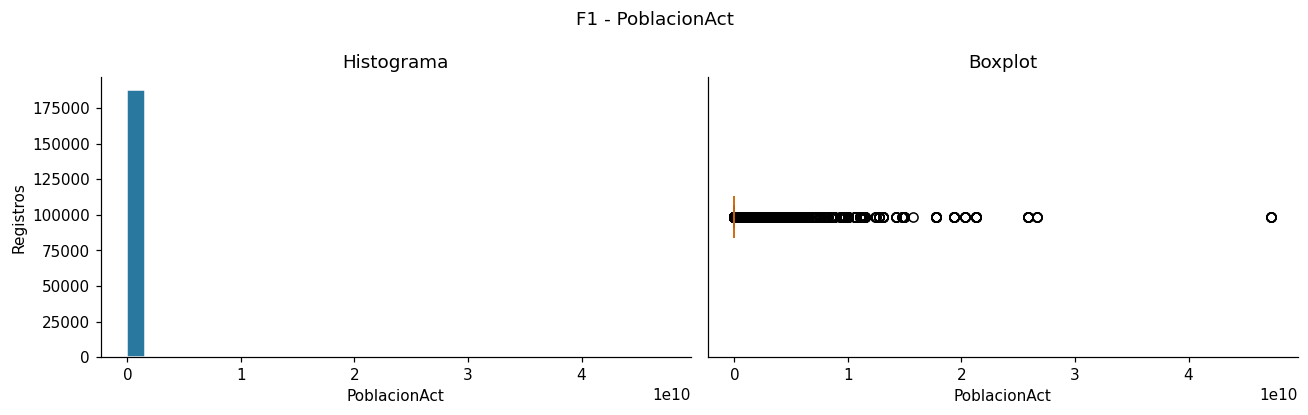

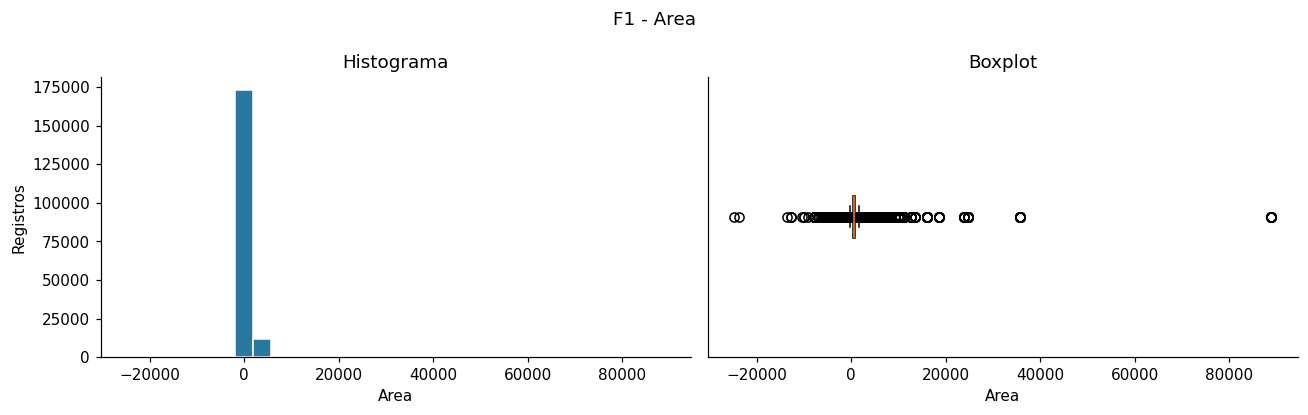

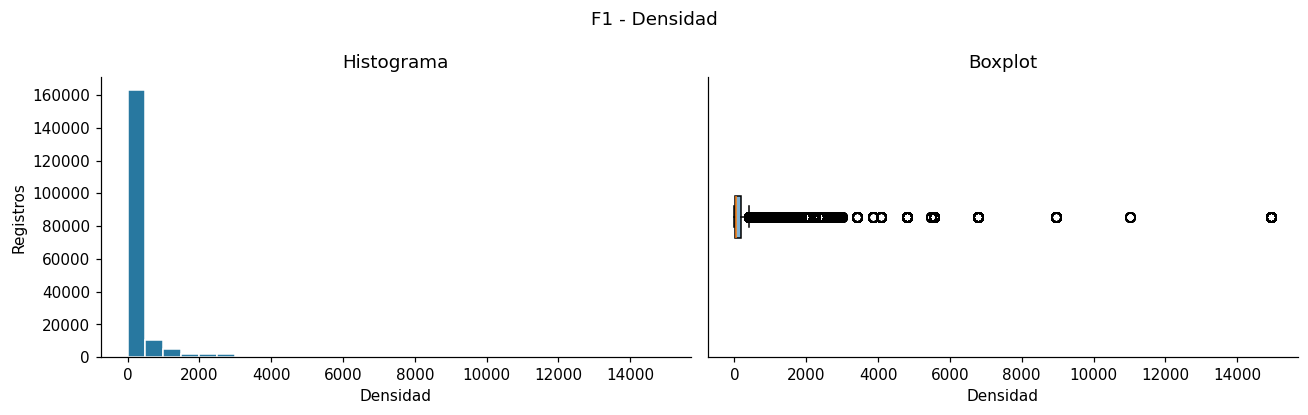

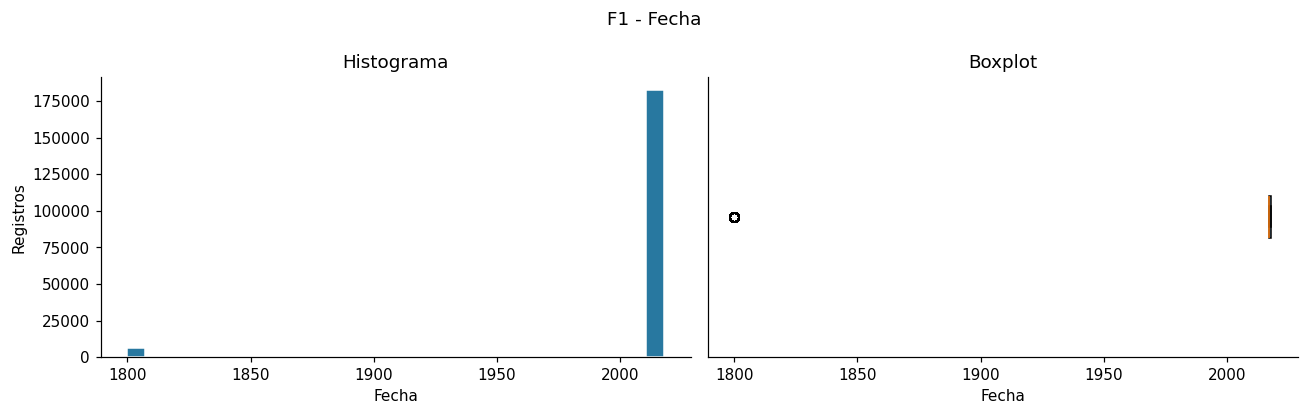

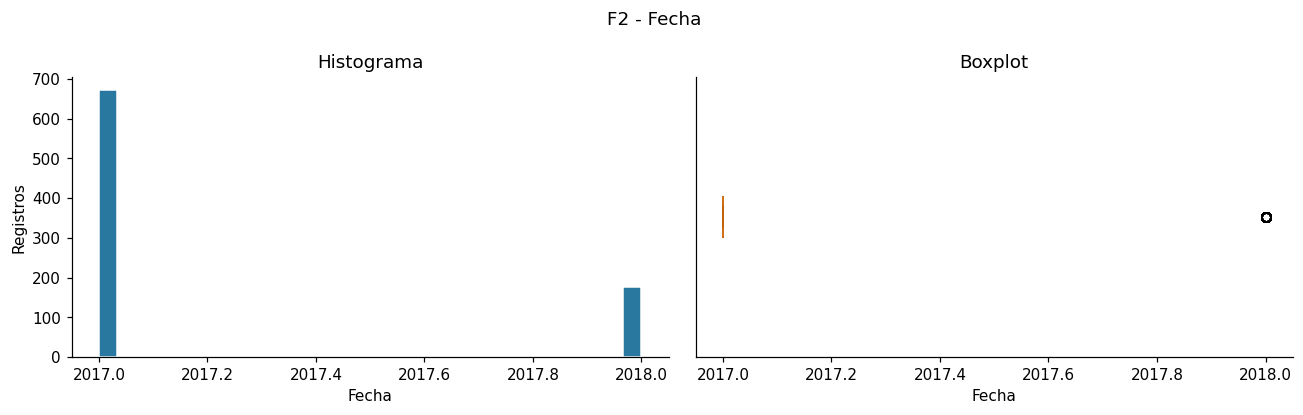

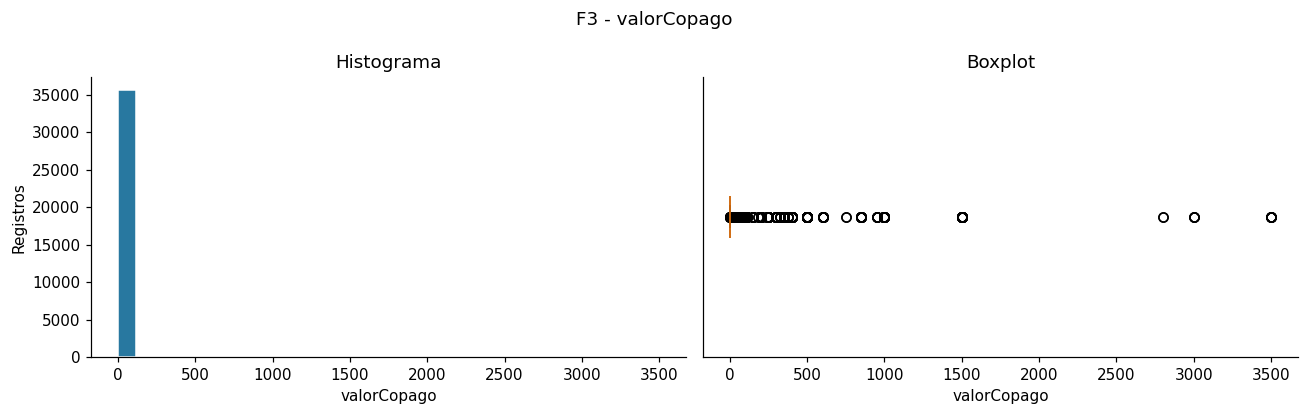

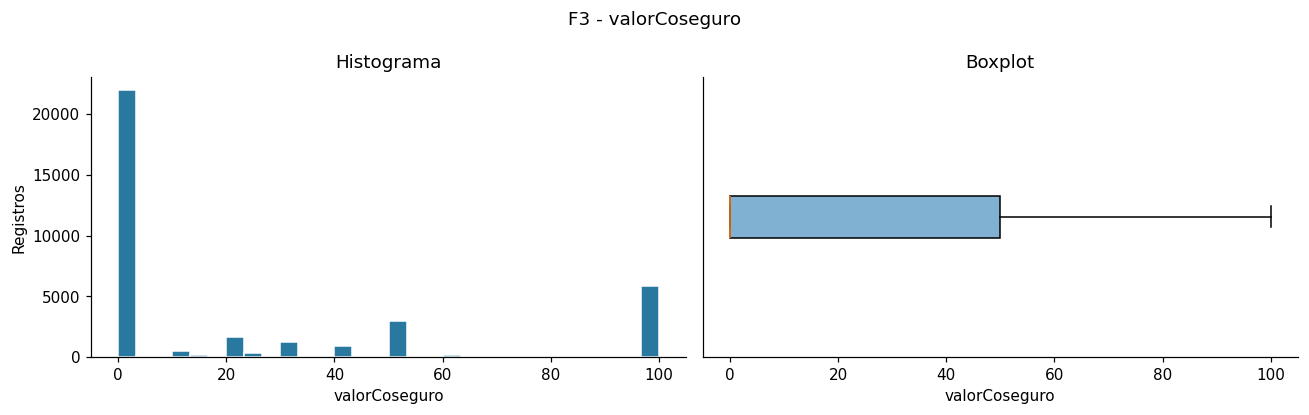

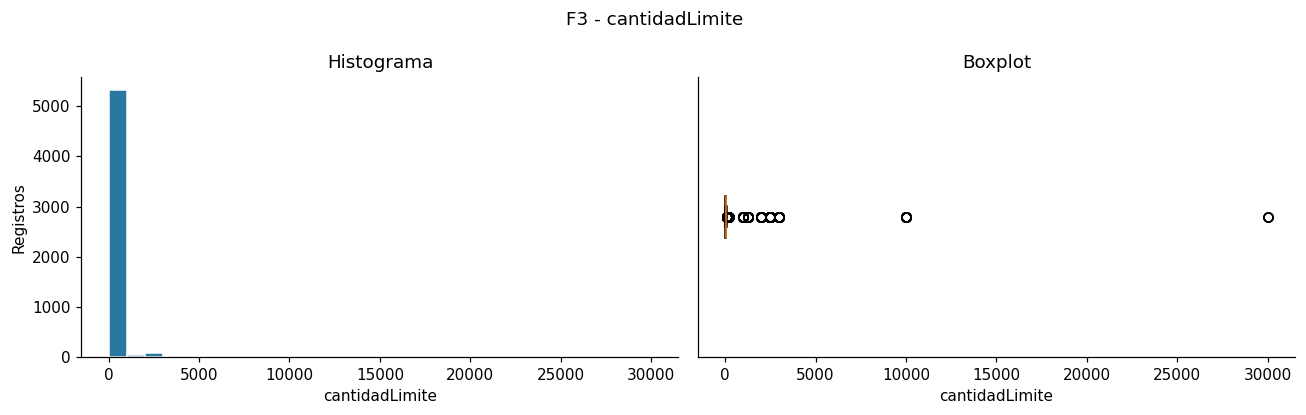

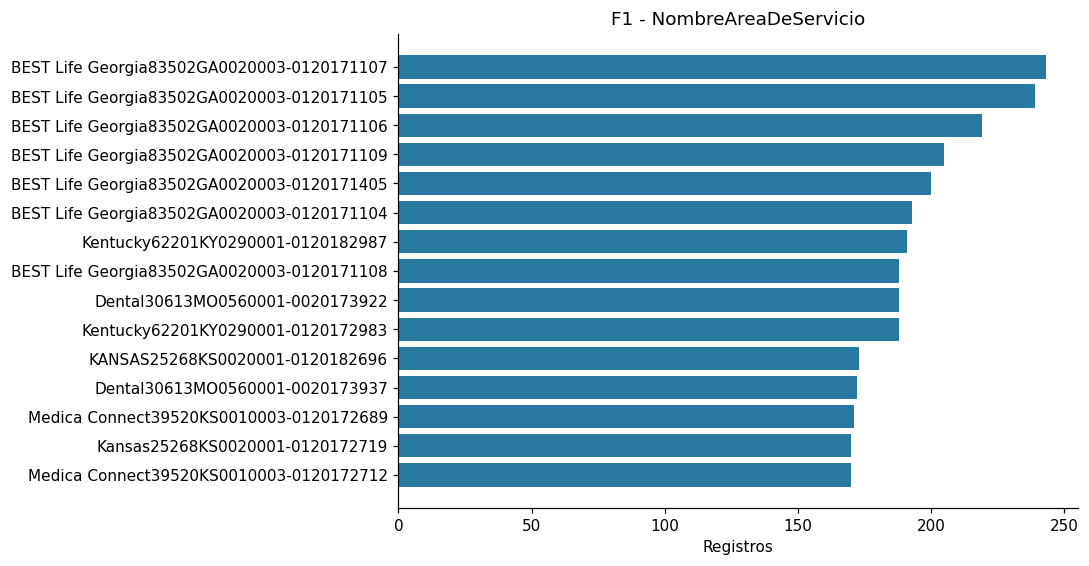

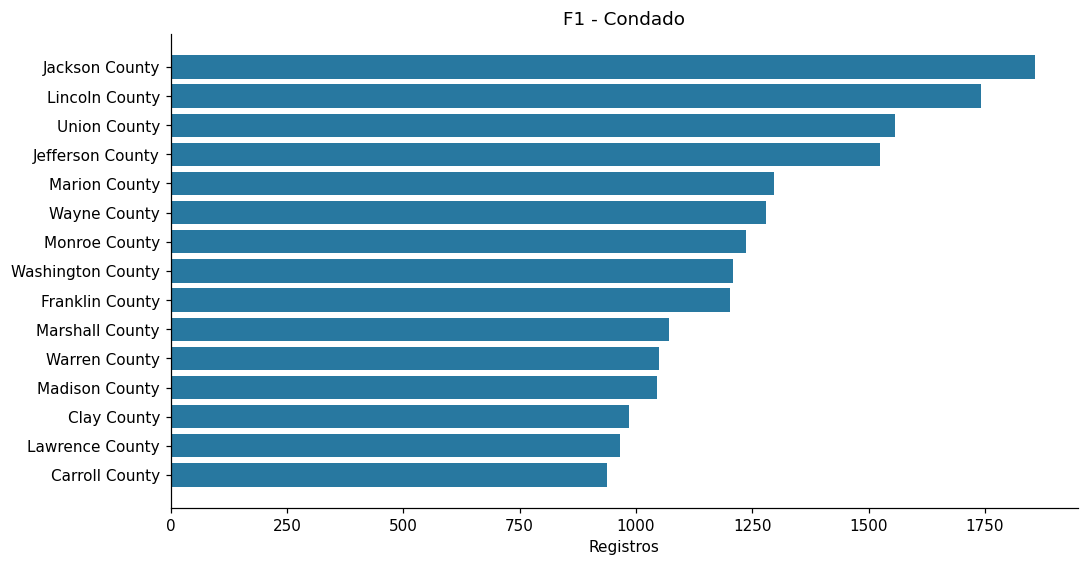

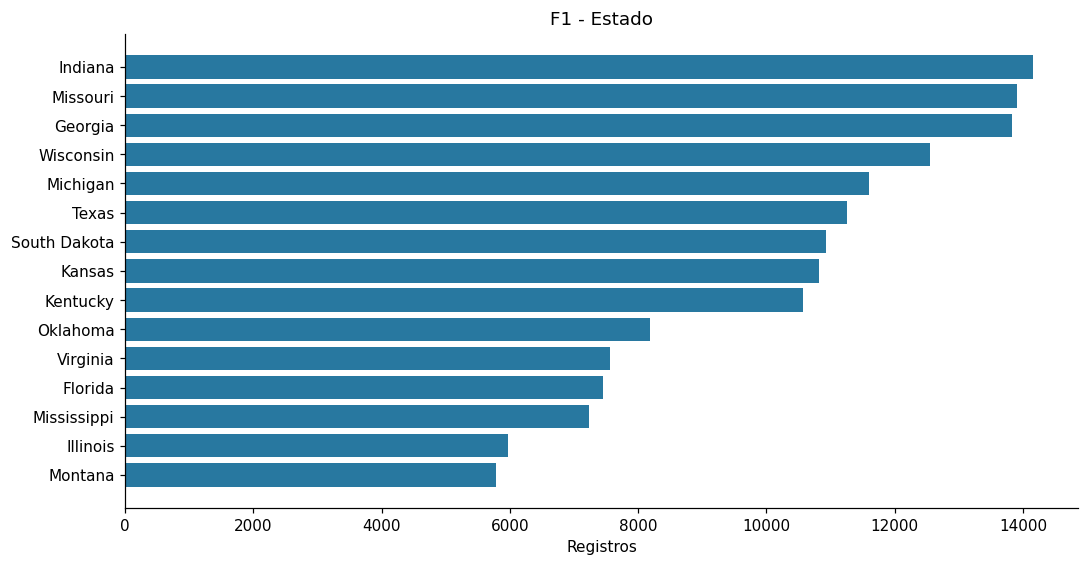

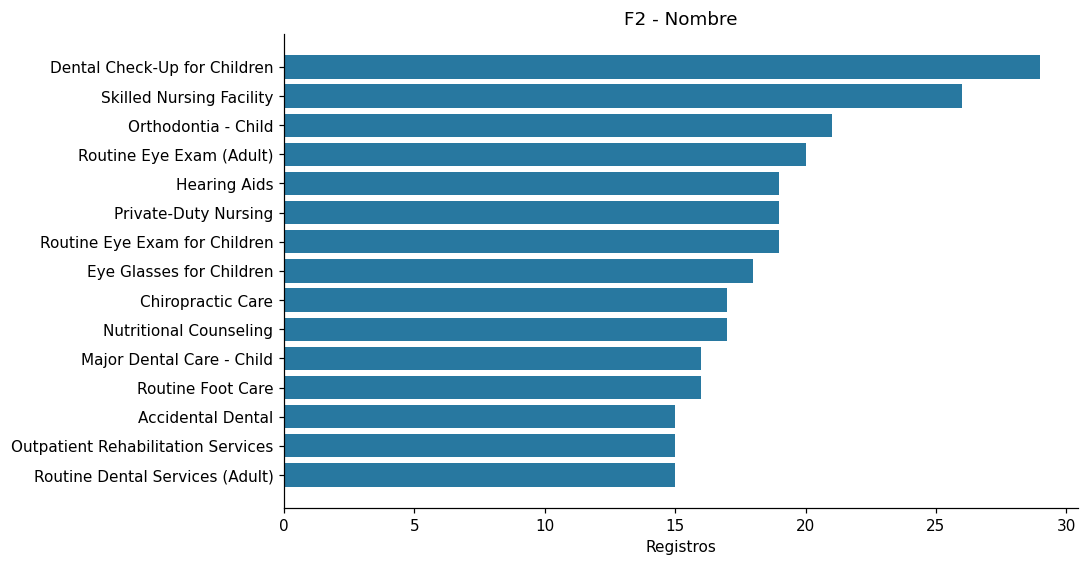

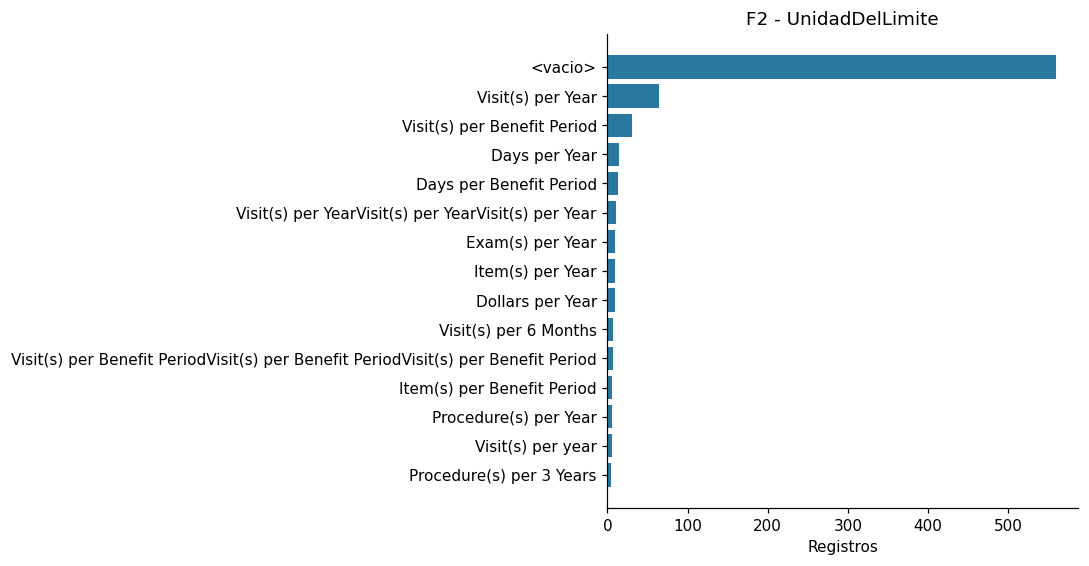

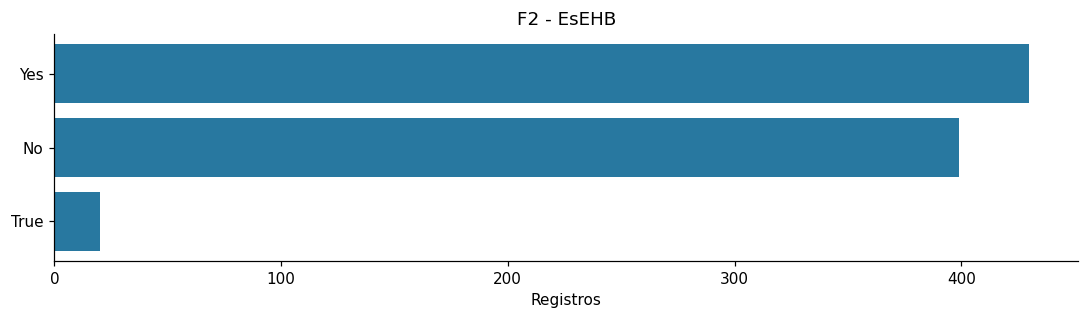

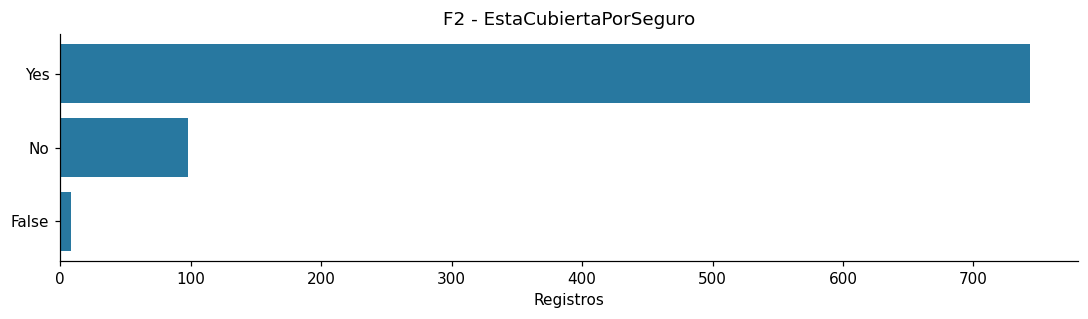

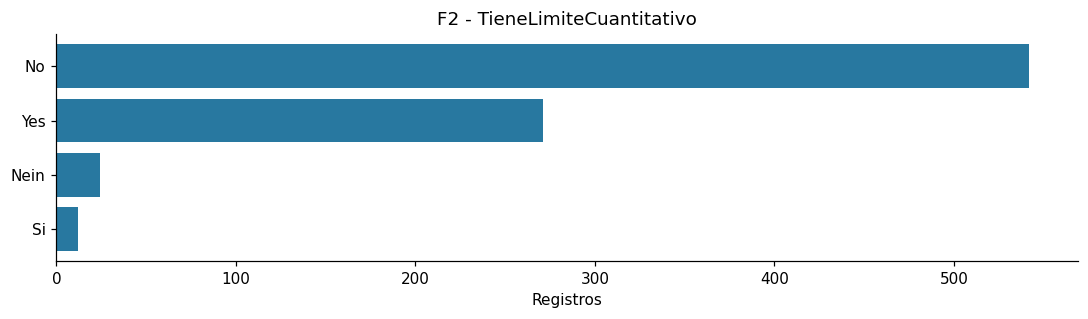

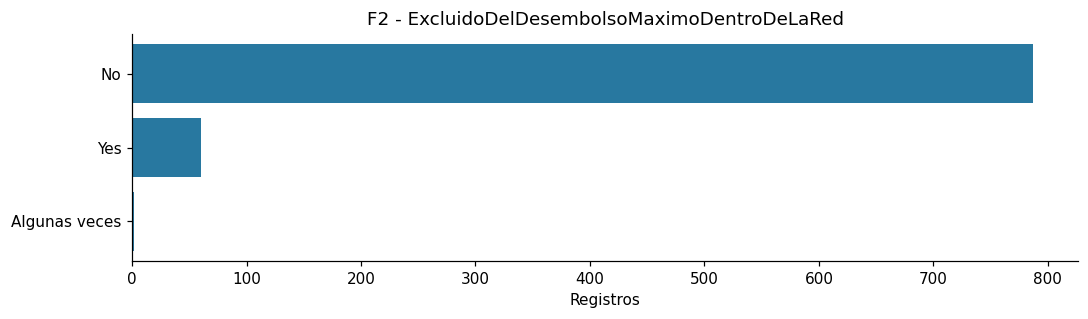

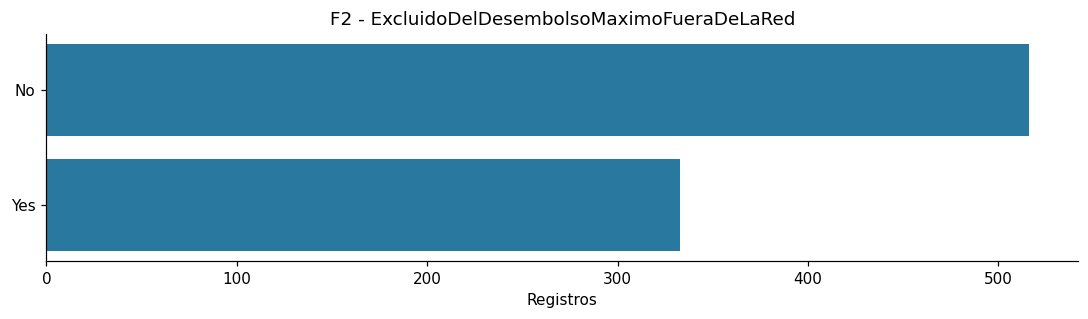

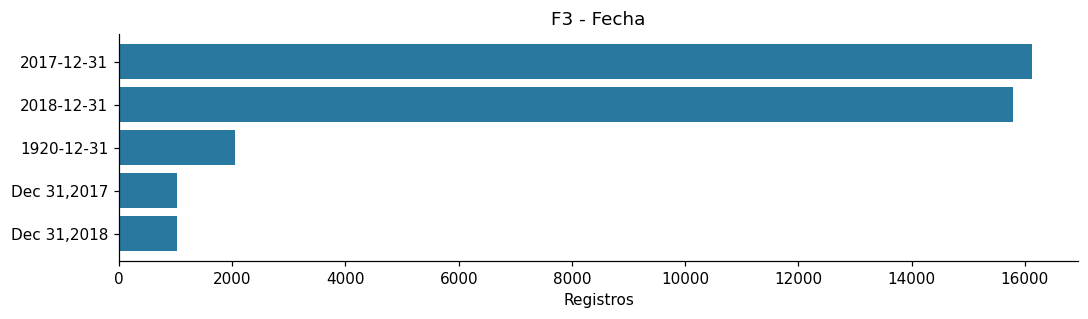

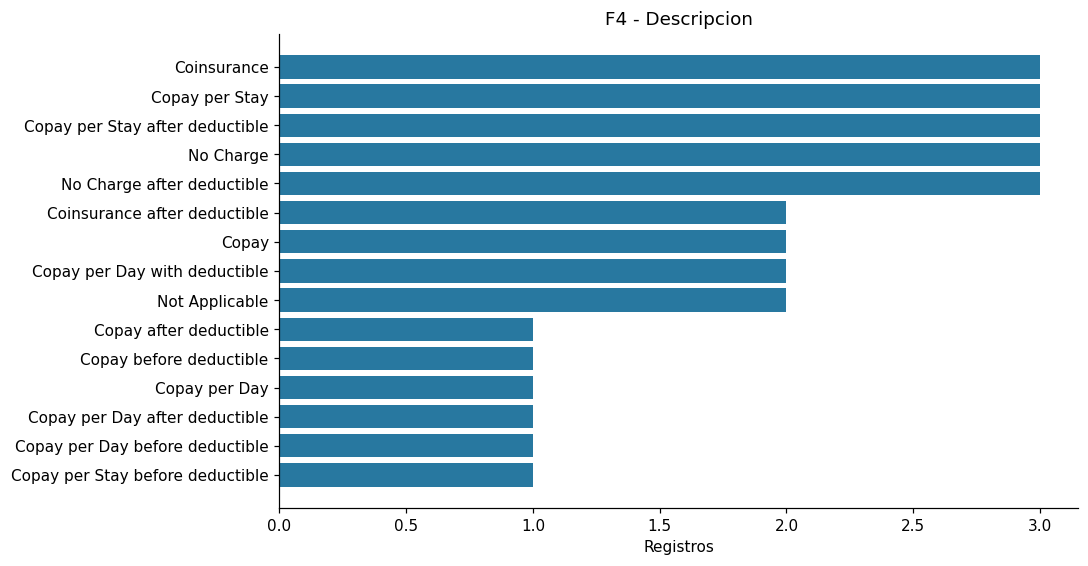

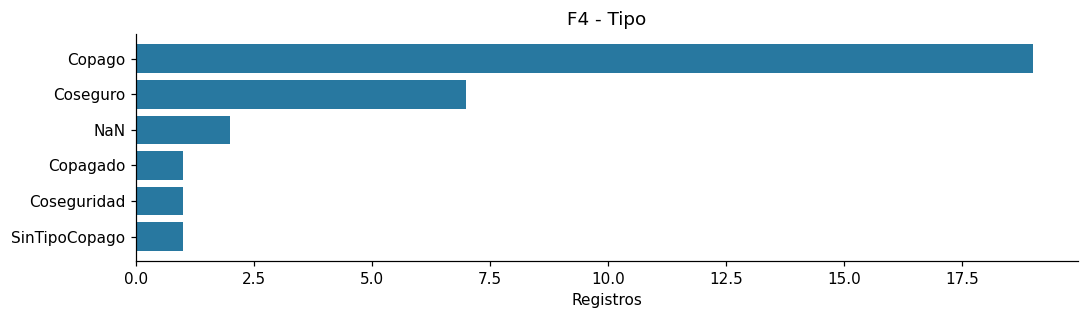

In [89]:
# Libreria de graficas
import matplotlib.pyplot as plt

# Histogramas y boxplots
for (fuente, nombre), valores in valores_numericos.items():
    if valores.empty:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].hist(valores, bins=30, color='#2878A0', edgecolor='white')
    axes[0].set(title='Histograma', xlabel=nombre, ylabel='Registros')
    axes[1].boxplot(valores, vert=False, patch_artist=True,
                    boxprops={'facecolor': '#80B1D3'})
    axes[1].set(title='Boxplot', xlabel=nombre, yticks=[])
    fig.suptitle(f'{fuente} - {nombre}')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# Barras de frecuencias
for (fuente, nombre), freq in frecuencias.items():
    if freq.empty:
        continue
    etiquetas = ['<NULL>' if pd.isna(v) else '<vacio>' if str(v).strip() == '' else str(v)
                 for v in freq['valor']]
    posiciones = range(len(freq))
    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(freq))))
    ax.barh(posiciones, freq['count'], color='#2878A0')
    ax.set_yticks(list(posiciones), etiquetas)
    ax.invert_yaxis()
    ax.set(title=f'{fuente} - {nombre}', xlabel='Registros')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

* Los histogramas muestran la distribución y los boxplots permiten observar dispersión y valores extremos. 

* Los puntos fuera de los bigotes no implican errores directamente, valores atipicos de la operación que pueden existir.

* Las barras muestran la concentración entre los valores más frecuentes y no representan necesariamente participación de mercado en el caso de negocio RaSa.

## 4. Referencias declaradas por RaSA en el caso: contraste descriptivo con lo encontrado en BD

* Se comparan identificadores distintos con las cifras del enunciado. En F4 se cuentan condiciones por las etiquetas exactas Copago y Coseguro, sin corregir otras etiquetas.

* En F3 se extrae el año de cuatro digitos de Fecha para agrupar ambos formatos observados; se excluyen identificadores de plan nulos o vacios.

In [90]:
# Comparaciones con el enunciado
contrastes = []

def registrar(referencia, observado, esperado, definicion):
    estado = 'Sin datos' if observado is None else ('Coincide' if observado == esperado else 'Difiere')
    contrastes.append({'referencia': referencia, 'observado': str(observado),
                      'esperado': str(esperado), 'estado': estado, 'definicion': definicion})

# Areas y beneficios distintos
for fuente, columna, esperado in [
    ('F1', 'IdAreaDeServicio_T', 5409),
    ('F2', 'IdTipoBeneficio_T', 170),
]:
    observado = datos[fuente].agg(F.countDistinct(col(columna))).first()[0]
    registrar(f'{fuente}: {columna}', observado, esperado, 'Identificadores distintos no nulos.')

# Condiciones por tipo
for tipo, esperado in [('Copago', 15), ('Coseguro', 5)]:
    observado = (datos['F4'].where(F.col('Tipo') == tipo)
                 .agg(F.countDistinct('IdCondicionesDePago_T')).first()[0])
    registrar(f'F4: Condiciones de {tipo}', observado, esperado,
              'IdCondicionesDePago_T distintos; filtro exacto de Tipo, sin normalizar etiquetas.')

# Periodos de areas y beneficios
for fuente in ['F1', 'F2']:
    valores = datos[fuente].select(F.col('Fecha').cast('string')).distinct().collect()
    observado = sorted([r[0] for r in valores], key=str)
    registrar(f'{fuente}: periodos', observado, ['2017', '2018', '2019'], 'Valores distintos de Fecha.')

# Año de los planes
planes = datos['F3'].withColumn('AnioConsulta', F.regexp_extract('Fecha', r'(\d{4})', 1))
for periodo, esperado in [('2017', 301), ('2018', 422)]:
    observado = (planes.where((F.col('AnioConsulta') == periodo) &
                              F.col('IdPlan_T').isNotNull() & (F.trim('IdPlan_T') != ''))
                 .agg(F.countDistinct('IdPlan_T')).first()[0])
    registrar(f'F3: Planes en {periodo}', observado, esperado,
              'IdPlan_T distintos no vacios; año extraido de Fecha.')

# Costos de 2018
for columna, esperado in [('valorCopago', 3300), ('valorCoseguro', 100)]:
    observado = planes.where(F.col('AnioConsulta') == '2018').agg(F.max(col(columna))).first()[0]
    registrar(f'F3: Maximo de {columna} en 2018', observado, esperado, 'Maximo del campo numerico por año.')

# Resumen de comparaciones
display(pd.DataFrame(contrastes))


,referencia,observado,esperado,estado,definicion
0,F1: IdAreaDeServicio_T,5409,5409,Coincide,Identificadores distintos no nulos.
1,F2: IdTipoBeneficio_T,178,170,Difiere,Identificadores distintos no nulos.
2,F4: Condiciones de Copago,14,15,Difiere,IdCondicionesDePago_T distintos; filtro exacto...
3,F4: Condiciones de Coseguro,5,5,Coincide,IdCondicionesDePago_T distintos; filtro exacto...
4,F1: periodos,"['1800', '2017', '2018']","['2017', '2018', '2019']",Difiere,Valores distintos de Fecha.
5,F2: periodos,"['2017', '2018']","['2017', '2018', '2019']",Difiere,Valores distintos de Fecha.
6,F3: Planes en 2017,202,301,Difiere,IdPlan_T distintos no vacios; año extraido de ...
7,F3: Planes en 2018,286,422,Difiere,IdPlan_T distintos no vacios; año extraido de ...
8,F3: Maximo de valorCopago en 2018,3500,3300,Difiere,Maximo del campo numerico por año.
9,F3: Maximo de valorCoseguro en 2018,100,100,Coincide,Maximo del campo numerico por año.


* Las diferencias requieren interpretacion; no prueban por si solas un error, ya que pueden indicar la realidad de la operación y hizo falta revisión en el levantamiento del requerimiento del caso de negocio RaSa